# Bioactive Molecule Prediction Using Extreme Gradient Boosting

**Target:** ChEMBL230 bioactivity dataset (IC50 assay records)
**Base paper:** Mustapha & Saeed, *Molecules* 2016


## Section 2 — Imports and Configuration

In [4]:
!pip install -q rdkit xgboost

In [5]:
# ----- Core data handling -----
import json
import time
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- Chemistry -----
from rdkit import Chem
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

# ----- Modelling -----
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import BernoulliNB
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, f1_score, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

import joblib

# ----- Project configuration (single source of truth) -----
RANDOM_STATE = 42
FINGERPRINT_RADIUS = 2
FINGERPRINT_BITS = 2048
HOLDOUT_FRACTION = 0.30
N_CV_FOLDS = 10
DECISION_THRESHOLD = 0.5     # probability cut-off used to turn scores into Active / Inactive

np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print(f"Random state        : {RANDOM_STATE}")
print(f"Fingerprint radius  : {FINGERPRINT_RADIUS}")
print(f"Fingerprint bits    : {FINGERPRINT_BITS}")
print(f"Holdout fraction    : {HOLDOUT_FRACTION}")
print(f"CV folds            : {N_CV_FOLDS}")
print(f"Decision threshold  : {DECISION_THRESHOLD}")

Libraries imported successfully.
Random state        : 42
Fingerprint radius  : 2
Fingerprint bits    : 2048
Holdout fraction    : 0.3
CV folds            : 10
Decision threshold  : 0.5


## Section 3 — Load the Raw Dataset


In [6]:
import pandas as pd

path = "CHEMBL230_RAW_DATA.csv"
df = pd.read_csv(path)

print("Raw file:", path)
print("Raw dataset shape:", df.shape)

Raw file: CHEMBL230_RAW_DATA.csv
Raw dataset shape: (7979, 5)


## Section 4 — Inspect the Raw Data

In [7]:
print("Columns:")
for c in df.columns:
    print(" -", c)

print()
print("Data types:")
print(df.dtypes)

print()
print("Missing values per column:")
print(df.isna().sum())

print()
print("Fully duplicated rows:", df.duplicated().sum())

print()
print("Standard Type value counts:")
print(df["Standard Type"].value_counts(dropna=False))

print()
print("Standard Units value counts:")
print(df["Standard Units"].value_counts(dropna=False))

print()
print("Standard Value summary statistics:")
print(df["Standard Value"].describe())

Columns:
 - Molecule ChEMBL ID
 - Smiles
 - Standard Type
 - Standard Value
 - Standard Units

Data types:
Molecule ChEMBL ID     object
Smiles                 object
Standard Type          object
Standard Value        float64
Standard Units         object
dtype: object

Missing values per column:
Molecule ChEMBL ID       0
Smiles                 190
Standard Type          157
Standard Value        1139
Standard Units        1120
dtype: int64

Fully duplicated rows: 602

Standard Type value counts:
Standard Type
IC50    7822
NaN      157
Name: count, dtype: int64

Standard Units value counts:
Standard Units
nM         6832
NaN        1120
ug.mL-1      25
ug            1
%             1
Name: count, dtype: int64

Standard Value summary statistics:
count    6.840000e+03
mean     1.063770e+06
std      1.977218e+07
min      0.000000e+00
25%      1.000000e+02
50%      9.705000e+02
75%      1.000000e+04
max      8.333357e+08
Name: Standard Value, dtype: float64


## Section 5 — Raw Data Preprocessing


In [8]:
# Remove rows with missing required values, retain only IC50 measurements in nM,
# remove invalid numeric measurements, and drop exact duplicate assay records.
rows_before = len(df)
required_columns = ["Molecule ChEMBL ID", "Smiles", "Standard Type", "Standard Value", "Standard Units"]
clean_df = df.dropna(subset=required_columns).copy()
rows_after_nulls = len(clean_df)

clean_df["Standard Value"] = pd.to_numeric(clean_df["Standard Value"], errors="coerce")
clean_df = clean_df.dropna(subset=["Standard Value"])
clean_df = clean_df[np.isfinite(clean_df["Standard Value"]) & (clean_df["Standard Value"] > 0)]

# Keep only the intended assay type and unit before applying the activity threshold.
clean_df = clean_df[
    clean_df["Standard Type"].astype(str).str.strip().str.upper().eq("IC50")
    & clean_df["Standard Units"].astype(str).str.strip().str.lower().eq("nm")
].copy()
rows_after_filter = len(clean_df)

# Remove exact duplicate assay records; do not collapse distinct measurements by molecule ID.
rows_before_deduplication = len(clean_df)
clean_df = clean_df.drop_duplicates().reset_index(drop=True)
rows_after_deduplication = len(clean_df)

print(f"Raw rows                                      : {rows_before}")
print(f"Rows after removing null required values     : {rows_after_nulls}")
print(f"Rows after retaining IC50 measurements in nM : {rows_after_filter}")
print(f"Exact duplicate records removed              : {rows_before_deduplication - rows_after_deduplication}")
print(f"Rows after duplicate removal                 : {rows_after_deduplication}")
print("Remaining Standard Types:", clean_df["Standard Type"].unique())
print("Remaining Standard Units:", clean_df["Standard Units"].unique())

if not clean_df["Standard Type"].eq("IC50").all():
    raise ValueError("Non-IC50 records remain after filtering.")
if not clean_df["Standard Units"].str.lower().eq("nm").all():
    raise ValueError("Non-nM records remain after filtering.")


Raw rows                                      : 7979
Rows after removing null required values     : 6839
Rows after retaining IC50 measurements in nM : 6806
Exact duplicate records removed              : 566
Rows after duplicate removal                 : 6240
Remaining Standard Types: ['IC50']
Remaining Standard Units: ['nM']


## Section 6 — SMILES Validation with RDKit



In [9]:
# RDKit SMILES Validation
clean_df["smiles_is_valid"] = clean_df["Smiles"].apply(lambda s: Chem.MolFromSmiles(s) is not None)

n_valid = clean_df["smiles_is_valid"].sum()
n_invalid = (~clean_df["smiles_is_valid"]).sum()
print(f"Valid SMILES: {n_valid} | Invalid SMILES: {n_invalid}")

if n_invalid > 0:
    clean_df = clean_df[clean_df["smiles_is_valid"]].reset_index(drop=True)
    print(f"Rows remaining: {len(clean_df)}")

clean_df = clean_df.drop(columns=["smiles_is_valid"])

Valid SMILES: 6240 | Invalid SMILES: 0


## Section 7 — Create the Activity Label from Standard Value


In [10]:
clean_df["Activity"] = np.where(
    clean_df["Standard Value"] < 10000,
    "Active",
    "Inactive",
)

n_exact_10000 = int((clean_df["Standard Value"] == 10000).sum())
n_active = int((clean_df["Activity"] == "Active").sum())
n_inactive = int((clean_df["Activity"] == "Inactive").sum())

print(f"Records with Standard Value exactly 10,000 : {n_exact_10000}")
print(f"Active records                             : {n_active}")
print(f"Inactive records                           : {n_inactive}")

if n_active + n_inactive != len(clean_df):
    raise ValueError("Activity labeling did not cover every cleaned record.")

Records with Standard Value exactly 10,000 : 219
Active records                             : 4469
Inactive records                           : 1771


## Section 8 — Assay Records vs. Molecule IDs



In [11]:
n_records = len(clean_df)
n_molecules = clean_df["Molecule ChEMBL ID"].nunique()

records_per_molecule = clean_df.groupby("Molecule ChEMBL ID").size()
n_molecules_multi_record = int((records_per_molecule > 1).sum())

labels_per_molecule = clean_df.groupby("Molecule ChEMBL ID")["Activity"].nunique()
n_molecules_conflicting = int((labels_per_molecule > 1).sum())

print(f"Total assay records after exact-deduplication       : {n_records}")
print(f"Total unique molecules                              : {n_molecules}")
print(f"Molecules with more than one distinct assay record  : {n_molecules_multi_record}")
print(f"Molecules with both Active and Inactive records     : {n_molecules_conflicting}")
print("Exact duplicate rows have been removed; distinct assay records for the same molecule are retained.")


Total assay records after exact-deduplication       : 6240
Total unique molecules                              : 4999
Molecules with more than one distinct assay record  : 809
Molecules with both Active and Inactive records     : 151
Exact duplicate rows have been removed; distinct assay records for the same molecule are retained.


## Section 9 — Save the Preprocessed Dataset

In [12]:
output_columns = [
    "Molecule ChEMBL ID", "Smiles", "Standard Type",
    "Standard Value", "Standard Units", "Activity"
]

v2_df = clean_df[output_columns].reset_index(drop=True)
v2_df.to_csv("CHEMBL230_Preprocessed_Data_V2.csv", index=False)

print(f"Saved preprocessed dataset to CHEMBL230_Preprocessed_Data_V2.csv with shape: {v2_df.shape}")

Saved preprocessed dataset to CHEMBL230_Preprocessed_Data_V2.csv with shape: (6240, 6)


## Section 10 — SMILES → Morgan Fingerprint


In [13]:
from rdkit.Chem import rdFingerprintGenerator

# Generate 2048-bit Morgan fingerprints (radius=2)
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=FINGERPRINT_RADIUS, fpSize=FINGERPRINT_BITS)
fingerprint_fn = lambda s: morgan_generator.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)).astype(np.int8)

X = np.vstack([fingerprint_fn(s) for s in v2_df["Smiles"]])
y = (v2_df["Activity"] == "Active").astype(int).values
molecule_ids = v2_df["Molecule ChEMBL ID"].values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution (1 = Active, 0 = Inactive):")
print(pd.Series(y).value_counts())

X shape: (6240, 2048)
y shape: (6240,)
Class distribution (1 = Active, 0 = Inactive):
1    4469
0    1771
Name: count, dtype: int64


## Section 11 — Molecule-Aware 70/30 Development / Holdout Split

In [14]:
splitter = GroupShuffleSplit(n_splits=1, test_size=HOLDOUT_FRACTION, random_state=RANDOM_STATE)
dev_idx, holdout_idx = next(splitter.split(X, y, groups=molecule_ids))

X_dev, X_holdout = X[dev_idx], X[holdout_idx]
y_dev, y_holdout = y[dev_idx], y[holdout_idx]
groups_dev, groups_holdout = molecule_ids[dev_idx], molecule_ids[holdout_idx]

overlap = set(groups_dev) & set(groups_holdout)
assert len(overlap) == 0, "Molecule overlap detected!"

print(f"Development: {X_dev.shape[0]} records, {len(set(groups_dev))} unique molecules")
print(f"Holdout:     {X_holdout.shape[0]} records, {len(set(groups_holdout))} unique molecules ({X_holdout.shape[0]/X.shape[0]:.1%} of total)")
print("Split successfully validated with zero molecule overlap.")

Development: 4380 records, 3499 unique molecules
Holdout:     1860 records, 1500 unique molecules (29.8% of total)
Split successfully validated with zero molecule overlap.


## Section 12 — Define the Six Models


In [15]:
model_builders = {
    "XGBoost": lambda: XGBClassifier(
        n_estimators=200, max_depth=16, learning_rate=0.2,
        gamma=0.16, min_child_weight=5,
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=100, max_depth=15, random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "SVM": lambda: CalibratedClassifierCV(
        LinearSVC(C=0.1, random_state=RANDOM_STATE, max_iter=5000),
        method="sigmoid", cv=3,
    ),
    "Naive Bayes": lambda: BernoulliNB(),
    "RBF": lambda: Pipeline([
        ("rbf_features", RBFSampler(gamma=0.01, n_components=500, random_state=RANDOM_STATE)),
        ("classifier", SGDClassifier(loss="log_loss", random_state=RANDOM_STATE, max_iter=1000)),
    ]),
    "ANN": lambda: MLPClassifier(
        hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
        alpha=1e-4, early_stopping=False, max_iter=300, batch_size=64,
        random_state=RANDOM_STATE,
    ),
}

print("Six models defined:", list(model_builders.keys()))

Six models defined: ['XGBoost', 'Random Forest', 'SVM', 'Naive Bayes', 'RBF', 'ANN']


## Section 13 — Evaluation Metric

In [16]:
def compute_metrics(y_true, scores, threshold=DECISION_THRESHOLD):
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    sen = tp / (tp + fn) if (tp + fn) else np.nan
    spc = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        "SEN": sen,
        "SPC": spc,
        "AUC": (sen + spc) / 2,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "ACC": (tp + tn) / len(y_true),
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
    }

## Section 14 — 10-Fold Molecule-Aware Cross-Validation (Validation Metrics)


In [17]:
def get_oof_scores(model_name, build_model, X_dev, y_dev, groups_dev, n_folds=N_CV_FOLDS):
    cv = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    oof_scores = np.full(len(y_dev), np.nan)
    group_overlap_count = 0

    for train_idx, val_idx in cv.split(X_dev, y_dev, groups=groups_dev):
        group_overlap_count += len(set(groups_dev[train_idx]) & set(groups_dev[val_idx]))
        model = build_model()
        model.fit(X_dev[train_idx], y_dev[train_idx])
        oof_scores[val_idx] = model.predict_proba(X_dev[val_idx])[:, 1]

    assert group_overlap_count == 0, f"{model_name}: molecule overlap found inside CV folds!"
    assert not np.isnan(oof_scores).any(), f"{model_name}: some records never got an OOF score!"
    return oof_scores

oof_scores = {}
thresholds = {}
cv_rows = []

for model_name, build_model in model_builders.items():
    scores = get_oof_scores(model_name, build_model, X_dev, y_dev, groups_dev)
    oof_scores[model_name] = scores
    thresholds[model_name] = DECISION_THRESHOLD

    row = {"Model": model_name, "Threshold": thresholds[model_name]}
    row.update(compute_metrics(y_dev, scores, thresholds[model_name]))
    cv_rows.append(row)
    print(f"{model_name:<15} | AUC: {row['AUC']:.4f} | SEN: {row['SEN']:.4f} | SPC: {row['SPC']:.4f}")

XGBoost         | AUC: 0.7594 | SEN: 0.9023 | SPC: 0.6164
Random Forest   | AUC: 0.6287 | SEN: 0.9813 | SPC: 0.2761
SVM             | AUC: 0.7030 | SEN: 0.9410 | SPC: 0.4650
Naive Bayes     | AUC: 0.6956 | SEN: 0.7462 | SPC: 0.6450
RBF             | AUC: 0.6539 | SEN: 0.9226 | SPC: 0.3852
ANN             | AUC: 0.7569 | SEN: 0.8956 | SPC: 0.6181


## Section 15 — Validation Set: Ranking and Best-Model Selection




In [18]:
display_cols = ["Model", "SEN", "SPC", "AUC", "F1", "Precision", "ACC", "TP", "TN", "FP", "FN"]

# Rank models using development-set 10-fold out-of-fold validation results.
cv_table = pd.DataFrame(cv_rows).sort_values("AUC", ascending=False).reset_index(drop=True)
model_order = list(cv_table["Model"])

# Select the model using validation CV only (never using the final holdout/test results).
best_model_name = cv_table.iloc[0]["Model"]
best_threshold = thresholds[best_model_name]
selection_note = "highest paper-defined AUC = (SEN + SPC) / 2 from pooled 10-fold out-of-fold validation predictions"

print("Models ranked by 10-fold development validation AUC:")
ranked_cv_view = cv_table.copy()
ranked_cv_view.index = ranked_cv_view.index + 1
ranked_cv_view.index.name = "Validation rank"
display(ranked_cv_view[display_cols].round(4))
print(f"\nSelected model from validation CV: {best_model_name}")
print(f"Selection metric: {selection_note}")

# Fit every model on all development data, then evaluate once on the untouched holdout set.
fitted_models = {}
holdout_scores = {}
holdout_rows = []

for model_name, build_model in model_builders.items():
    print(f"Training {model_name} on the full development set ...")
    model = build_model()
    model.fit(X_dev, y_dev)
    fitted_models[model_name] = model

    scores = model.predict_proba(X_holdout)[:, 1]
    holdout_scores[model_name] = scores

    row = {"Model": model_name, "Threshold": thresholds[model_name]}
    row.update(compute_metrics(y_holdout, scores, thresholds[model_name]))
    holdout_rows.append(row)

# Preserve validation ranking in the test-results table; do not rank/select using test metrics.
holdout_table = pd.DataFrame(holdout_rows).set_index("Model").loc[model_order].reset_index()
best_model = fitted_models[best_model_name]

print("\nFinal holdout/test metrics (displayed in validation-rank order; not used for selection):")
display(holdout_table[display_cols].round(4))
print(f"\nSelected model: {best_model_name}")
print("The holdout set is reserved for final evaluation only.")


Models ranked by 10-fold development validation AUC:


,Model,SEN,SPC,AUC,F1,Precision,ACC,TP,TN,FP,FN
Validation rank,,,,,,,,,,,
1,XGBoost,0.9023,0.6164,0.7594,0.8795,0.8579,0.8221,2844,757,471,308
2,ANN,0.8956,0.6181,0.7569,0.8762,0.8575,0.8178,2823,759,469,329
3,SVM,0.9410,0.4650,0.7030,0.8756,0.8187,0.8075,2966,571,657,186
4,Naive Bayes,0.7462,0.6450,0.6956,0.7919,0.8436,0.7178,2352,792,436,800
5,RBF,0.9226,0.3852,0.6539,0.8534,0.7939,0.7719,2908,473,755,244
6,Random Forest,0.9813,0.2761,0.6287,0.8671,0.7767,0.7836,3093,339,889,59



Selected model from validation CV: XGBoost
Selection metric: highest paper-defined AUC = (SEN + SPC) / 2 from pooled 10-fold out-of-fold validation predictions
Training XGBoost on the full development set ...
Training Random Forest on the full development set ...
Training SVM on the full development set ...
Training Naive Bayes on the full development set ...
Training RBF on the full development set ...
Training ANN on the full development set ...

Final holdout/test metrics (displayed in validation-rank order; not used for selection):


,Model,SEN,SPC,AUC,F1,Precision,ACC,TP,TN,FP,FN
0,XGBoost,0.9005,0.6169,0.7587,0.8750,0.8508,0.8177,1186,335,208,131
1,ANN,0.9142,0.5912,0.7527,0.8779,0.8443,0.8199,1204,321,222,113
2,SVM,0.9484,0.4328,0.6906,0.8692,0.8022,0.7978,1249,235,308,68
3,Naive Bayes,0.7388,0.6372,0.6880,0.7825,0.8316,0.7091,973,346,197,344
4,RBF,0.8876,0.5101,0.6989,0.8496,0.8146,0.7774,1169,277,266,148
5,Random Forest,0.9863,0.2928,0.6396,0.8660,0.7718,0.7839,1299,159,384,18



Selected model: XGBoost
The holdout set is reserved for final evaluation only.


## Section 16 — Development Validation (10-Fold Out-of-Fold) Metrics


In [25]:
cv_view = cv_table.copy()
cv_view.index = cv_view.index + 1
cv_view.index.name = "Validation rank"

print("Development validation metrics from pooled 10-fold out-of-fold predictions:")
display(cv_view[display_cols].round(4))

best_row = holdout_table[holdout_table["Model"] == best_model_name].iloc[0]
best_cv_row = cv_table[cv_table["Model"] == best_model_name].iloc[0]

print()
print(f"Selected model (chosen using validation CV): {best_model_name}")
print(f"  Validation CV : AUC = {best_cv_row['AUC']:.4f} | SEN = {best_cv_row['SEN']:.4f} | SPC = {best_cv_row['SPC']:.4f} "
      f"| F1 = {best_cv_row['F1']:.4f} | FP = {best_cv_row['FP']}, FN = {best_cv_row['FN']}")
print(f"  Final test    : AUC = {best_row['AUC']:.4f} | SEN = {best_row['SEN']:.4f} | SPC = {best_row['SPC']:.4f} "
      f"| F1 = {best_row['F1']:.4f} | FP = {best_row['FP']}, FN = {best_row['FN']}")
print(f"  Final test accuracy = {best_row['ACC']:.4f}")

assert best_model_name == cv_table.iloc[0]["Model"]


Development validation metrics from pooled 10-fold out-of-fold predictions:


,Model,SEN,SPC,AUC,F1,Precision,ACC,TP,TN,FP,FN
Validation rank,,,,,,,,,,,
1,XGBoost,0.9023,0.6164,0.7594,0.8795,0.8579,0.8221,2844,757,471,308
2,ANN,0.8956,0.6181,0.7569,0.8762,0.8575,0.8178,2823,759,469,329
3,SVM,0.9410,0.4650,0.7030,0.8756,0.8187,0.8075,2966,571,657,186
4,Naive Bayes,0.7462,0.6450,0.6956,0.7919,0.8436,0.7178,2352,792,436,800
5,RBF,0.9226,0.3852,0.6539,0.8534,0.7939,0.7719,2908,473,755,244
6,Random Forest,0.9813,0.2761,0.6287,0.8671,0.7767,0.7836,3093,339,889,59



Selected model (chosen using validation CV): XGBoost
  Validation CV : AUC = 0.7594 | SEN = 0.9023 | SPC = 0.6164 | F1 = 0.8795 | FP = 471, FN = 308
  Final test    : AUC = 0.7587 | SEN = 0.9005 | SPC = 0.6169 | F1 = 0.8750 | FP = 208, FN = 131
  Final test accuracy = 0.8177


## Section 17 — ROC Curves, Metric Comparison and Confusion Matrices


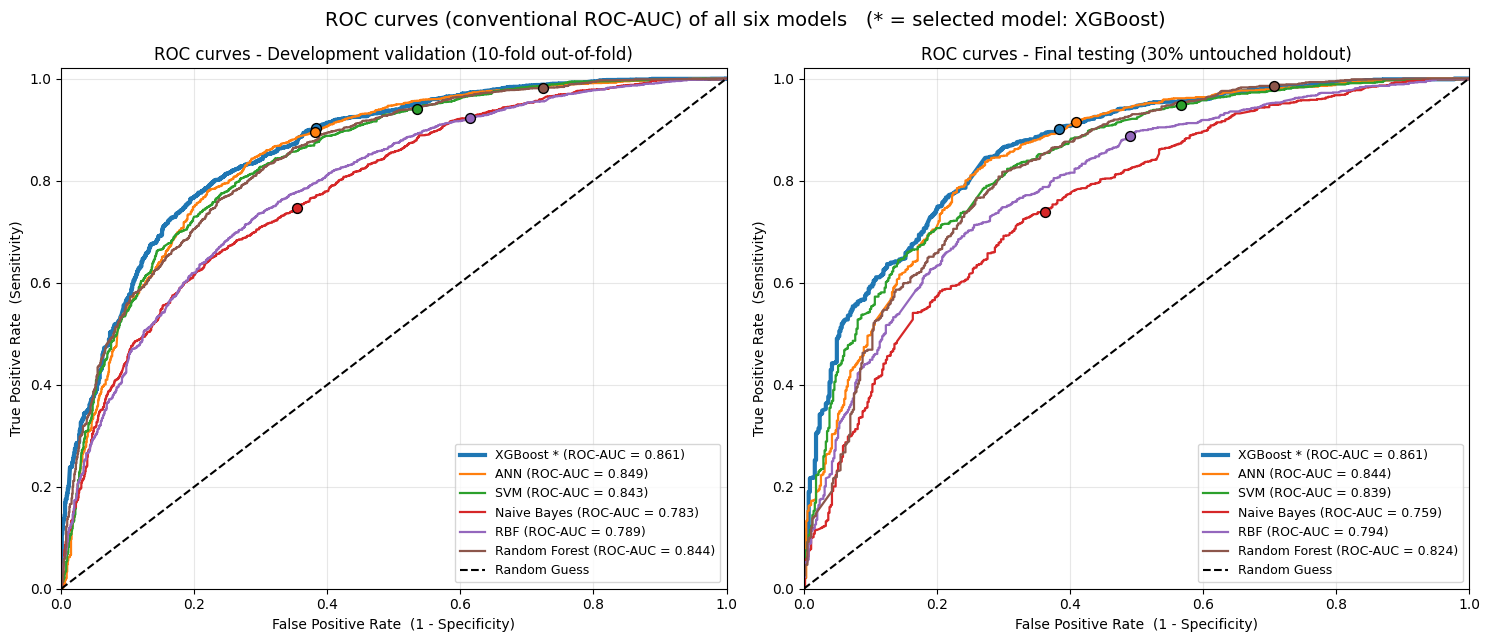

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

colors = {name: plt.get_cmap("tab10")(i) for i, name in enumerate(model_order)}

def plot_roc_panel(ax, y_true, score_dict, title):
    for name in model_order:
        scores = score_dict[name]
        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = roc_auc_score(y_true, scores)

        width = 3.0 if name == best_model_name else 1.6
        star = " *" if name == best_model_name else ""
        ax.plot(fpr, tpr, color=colors[name], lw=width,
                label=f"{name}{star} (ROC-AUC = {roc_auc:.3f})")

        m = compute_metrics(y_true, scores, thresholds[name])
        ax.scatter(1 - m["SPC"], m["SEN"], color=colors[name],
                   edgecolor="black", s=50, zorder=3)

    ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guess")
    ax.set_xlabel("False Positive Rate  (1 - Specificity)")
    ax.set_ylabel("True Positive Rate  (Sensitivity)")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_roc_panel(axes[0], y_dev, oof_scores, "ROC curves - Development validation (10-fold out-of-fold)")
plot_roc_panel(axes[1], y_holdout, holdout_scores, "ROC curves - Final testing (30% untouched holdout)")
fig.suptitle(f"ROC curves (conventional ROC-AUC) of all six models   (* = selected model: {best_model_name})", fontsize=14)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

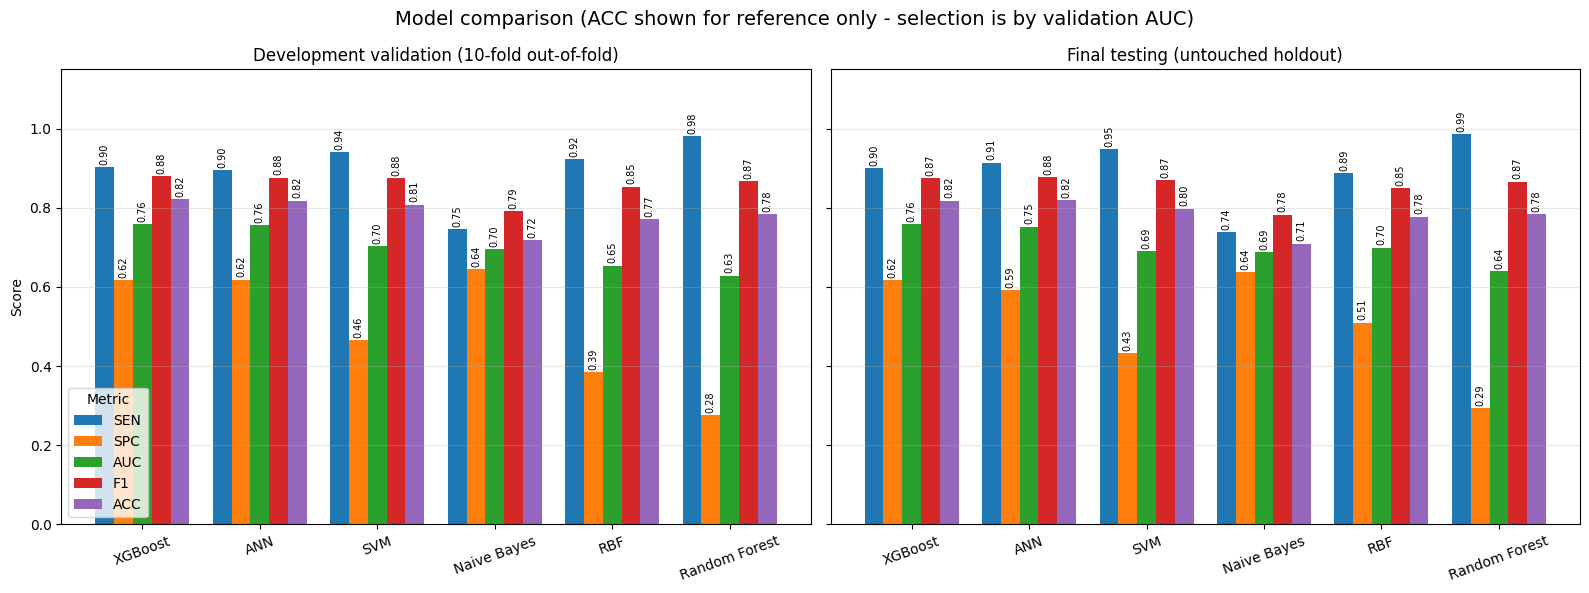

In [21]:
# ---- Grouped bar chart: SEN, SPC, AUC, F1 (and ACC for reference) per model ----
metric_cols = ["SEN", "SPC", "AUC", "F1", "ACC"]
x = np.arange(len(model_order))
width = 0.16

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, table, title in [(axes[0], cv_table, "Development validation (10-fold out-of-fold)"),
                         (axes[1], holdout_table, "Final testing (untouched holdout)")]:
    for i, metric in enumerate(metric_cols):
        values = table[metric].values
        ax.bar(x + (i - 2) * width, values, width, label=metric)
        for j, v in enumerate(values):
            ax.text(x[j] + (i - 2) * width, v + 0.006, f"{v:.2f}",
                    ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=20)
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score")
axes[0].legend(title="Metric", loc="lower left")
fig.suptitle("Model comparison (ACC shown for reference only - selection is by validation AUC)", fontsize=14)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

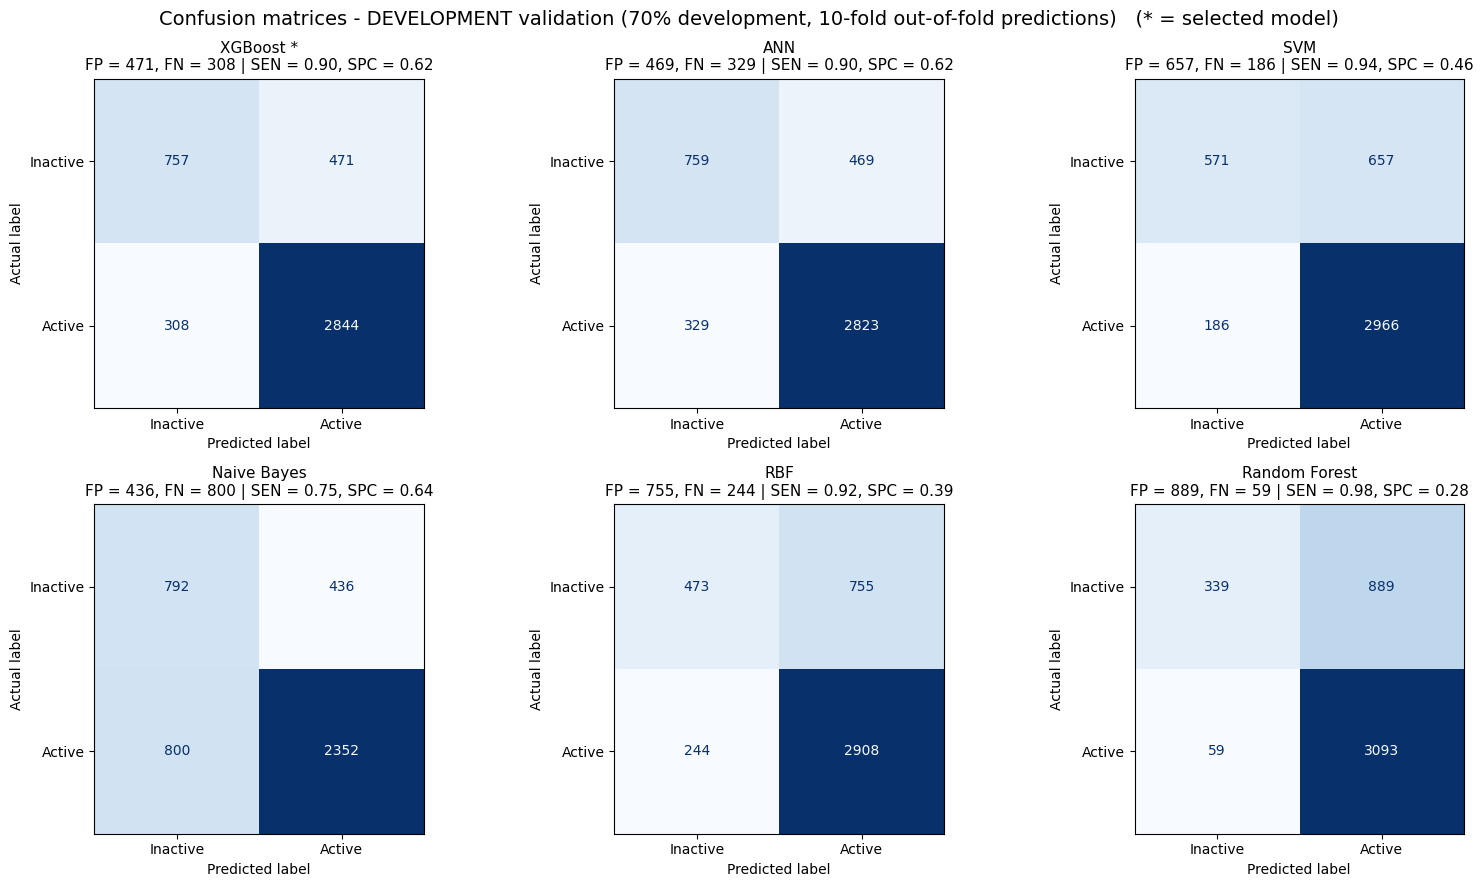

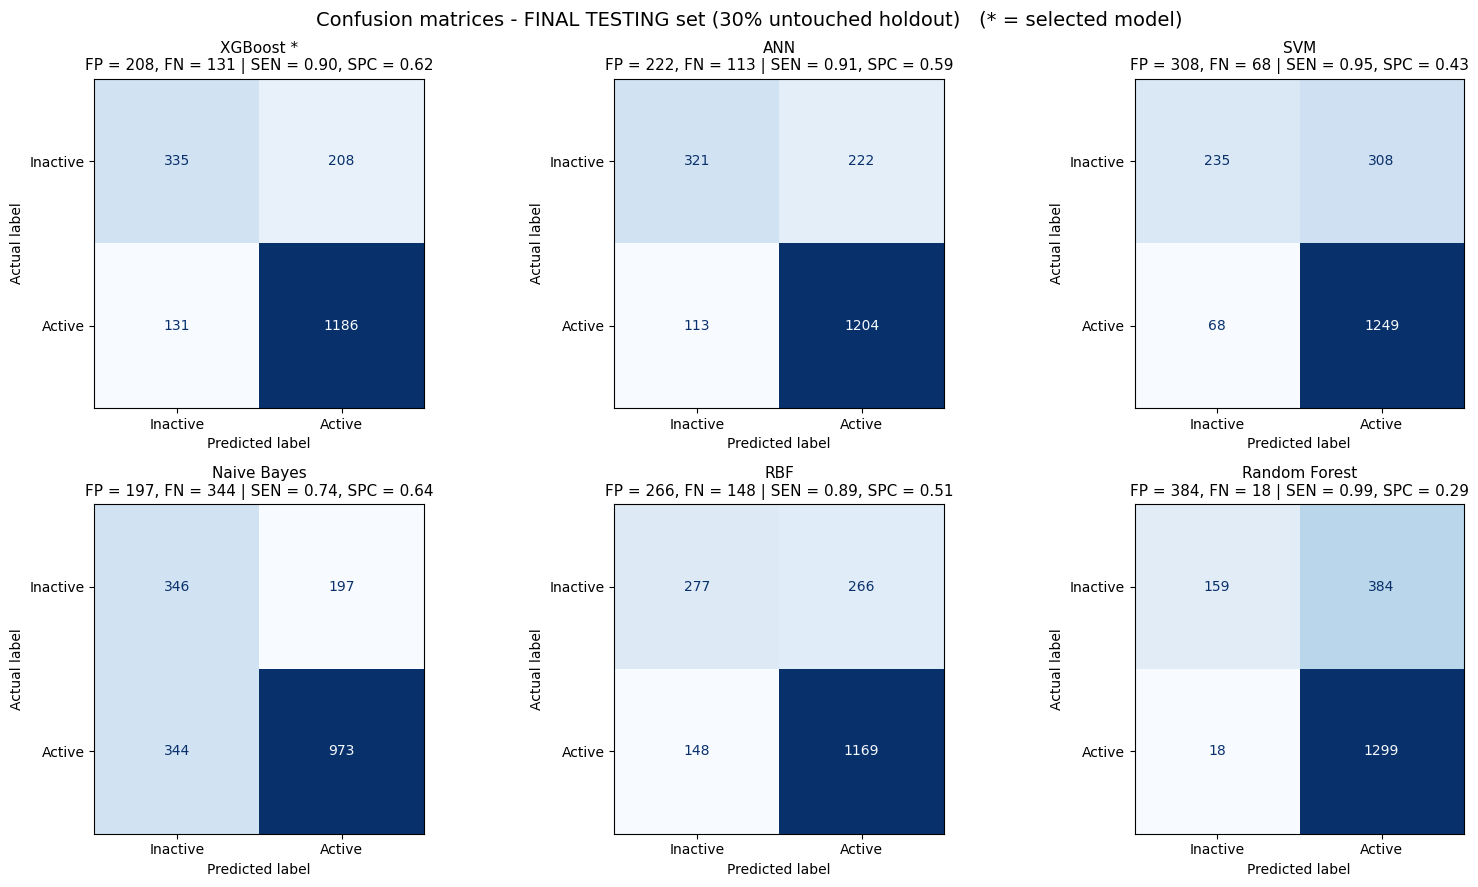

Saved confusion_matrices.json (keys: validation_cv, testing_holdout)


In [22]:
# ---- Confusion matrices of all six models: DEVELOPMENT VALIDATION (10-fold out-of-fold) and FINAL TESTING (holdout) ----
class_labels = ["Inactive", "Active"]
cm_results = {"validation_cv": {}, "testing_holdout": {}}

def plot_confusion_grid(y_true, score_dict, set_name, key, filename):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, name in zip(axes.ravel(), model_order):
        preds = (score_dict[name] >= thresholds[name]).astype(int)
        cm = confusion_matrix(y_true, preds, labels=[0, 1])
        cm_results[key][name] = cm.tolist()

        ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(
            ax=ax, values_format="d", cmap="Blues", colorbar=False
        )
        tn, fp, fn, tp = cm.ravel()
        sen, spc = tp / (tp + fn), tn / (tn + fp)
        star = " *" if name == best_model_name else ""
        ax.set_title(f"{name}{star}\nFP = {fp}, FN = {fn} | SEN = {sen:.2f}, SPC = {spc:.2f}", fontsize=11)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
    fig.suptitle(f"Confusion matrices - {set_name}   (* = selected model)", fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_confusion_grid(y_dev, oof_scores,
                    "DEVELOPMENT validation (70% development, 10-fold out-of-fold predictions)",
                    "validation_cv", "confusion_matrices_training.png")
plot_confusion_grid(y_holdout, holdout_scores,
                    "FINAL TESTING set (30% untouched holdout)",
                    "testing_holdout", "confusion_matrices_testing.png")

with open("confusion_matrices.json", "w") as f:
    json.dump(cm_results, f, indent=2)
print("Saved confusion_matrices.json (keys: validation_cv, testing_holdout)")

## Section 18 — Save the Final Model, Metrics and Metadata

In [23]:
joblib.dump(best_model, "best_model.pkl")
print("Saved best_model.pkl")

cv_table.to_csv("cv_results.csv", index=False)
holdout_table.to_csv("holdout_results.csv", index=False)
print("Saved cv_results.csv and holdout_results.csv")

def _to_python(obj):
    """Make numpy scalars JSON-serialisable."""
    return obj.item() if hasattr(obj, "item") else str(obj)

metadata = {
    "project_name": "Bioactive Molecule Prediction Using Extreme Gradient Boosting",
    "selected_model": best_model_name,
    "decision_threshold": best_threshold,
    "feature_type": "Morgan fingerprint (ECFP4-style)",
    "fingerprint_radius": FINGERPRINT_RADIUS,
    "fingerprint_bits": FINGERPRINT_BITS,
    "dataset_row_counts": {
        "raw_rows": int(rows_before),
        "rows_after_null_removal": int(rows_after_nulls),
        "rows_after_ic50_nM_filter": int(rows_after_filter),
        "exact_duplicate_rows_removed": int(rows_before_deduplication - rows_after_deduplication),
        "cleaned_rows": int(len(v2_df)),
        "development_rows": int(len(X_dev)),
        "holdout_rows": int(len(X_holdout)),
    },
    "development_holdout_split": {
        "holdout_fraction_target": HOLDOUT_FRACTION,
        "holdout_fraction_actual": len(X_holdout) / len(X),
        "split_type": "molecule-aware (GroupShuffleSplit)",
        "molecule_overlap": 0,
    },
    "cross_validation": {
        "folds": N_CV_FOLDS,
        "type": "StratifiedGroupKFold (molecule-aware, stratified)",
        "metrics_computed_from": "pooled out-of-fold predictions (no per-fold averaging)",
    },
    "model_selection": {
        "selected_on": "10-fold molecule-aware out-of-fold validation predictions from the 70% development set",
        "ranking_metric": "AUC = (Sensitivity + Specificity) / 2  (paper Eq. 11)",
        "accuracy_used_for_selection": False,
        "decision_threshold": DECISION_THRESHOLD,
        "reason": selection_note,
        "final_test_used_for_selection": False,
    },
    "cv_results": cv_table.to_dict(orient="records"),
    "holdout_results": holdout_table.to_dict(orient="records"),
    "random_state": RANDOM_STATE,
}

with open("metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=_to_python)

print("Saved metadata.json")

Saved best_model.pkl
Saved cv_results.csv and holdout_results.csv
Saved metadata.json


## Section 19 — Simple Prediction Function

In [24]:
def predict_molecule(smiles, model=None, threshold=None):
    if model is None:
        model = joblib.load("best_model.pkl")
    if threshold is None:
        with open("metadata.json") as f:
            threshold = json.load(f)["decision_threshold"]

    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {"smiles": smiles, "error": "Invalid SMILES string."}

    # Generate Morgan fingerprint (radius=2, 2048 bits)
    from rdkit.Chem import rdFingerprintGenerator
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = gen.GetFingerprintAsNumPy(mol).reshape(1, -1).astype(np.int8)

    prob = float(model.predict_proba(fp)[0, 1])
    return {
        "smiles": smiles,
        "predicted_class": "Active" if prob >= threshold else "Inactive",
        "probability_active": prob,
    }

# Quick validation test
test_smiles = [
    "CC1(C)OC(=O)C(OC2CCCCC2)=C1c1ccc(S(C)(=O)=O)cc1",
    "CS(=O)(=O)c1ccc(-c2csc(CC(=O)O)c2-c2ccc(F)cc2)cc1",
]
for s in test_smiles:
    print(predict_molecule(s, model=best_model, threshold=best_threshold))

{'smiles': 'CC1(C)OC(=O)C(OC2CCCCC2)=C1c1ccc(S(C)(=O)=O)cc1', 'predicted_class': 'Active', 'probability_active': 0.9535619020462036}
{'smiles': 'CS(=O)(=O)c1ccc(-c2csc(CC(=O)O)c2-c2ccc(F)cc2)cc1', 'predicted_class': 'Inactive', 'probability_active': 0.15707111358642578}


## Section 20 — Final Summary

```
Raw dataset
    |
Drop rows with missing required values and invalid/non-positive Standard Values
    |
Keep only Standard Type = IC50 and Standard Units = nM
    |
Remove exact duplicate assay records (retain distinct assays per molecule)
    |
SMILES validation (RDKit)
    |
Activity label from Standard Value (< 10,000 nM Active, >= 10,000 nM Inactive)
    |
Morgan fingerprints (radius 2, 2048 bits)
    |
70/30 molecule-aware development / untouched final-test split
    |
10-fold molecule-aware, stratified CV on development data
    |
Rank/select model using pooled out-of-fold validation AUC = (SEN + SPC) / 2
    |
Train all models on development data; evaluate once on untouched final-test data
    |
Save selected model, metrics, metadata, confusion matrices and plots
    |
predict_molecule(smiles) uses the selected model and threshold
```

The selected model is determined only from development-set cross-validation results. The 30% holdout set is not used for model selection and is reserved for final evaluation.
